In [7]:
import pandas as pd
import numpy as np

import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier, plot_tree

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

In [8]:
df = sns.load_dataset("titanic")
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [40]:
print("Dataset shape:", df.shape)
print("\nColumn name:", df.columns.tolist())
print("\nData types:", df.dtypes)
print("\nMissing values:", df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())
print("\nStatistical summary:", df.describe())
print("\nSurvival counts:", df["survived"].value_counts())
print("\nSurvival percentages:", df["survived"].value_counts(normalize=True) * 100)

Dataset shape: (891, 15)

Column name: ['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town', 'alive', 'alone']

Data types: survived          int64
pclass            int64
sex              object
age             float64
sibsp             int64
parch             int64
fare            float64
embarked         object
class          category
who              object
adult_male         bool
deck           category
embark_town      object
alive            object
alone              bool
dtype: object

Missing values: survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64

Duplicate rows: 107

Statistical summary:          survived      pclass         age       sibsp       parch     

In [14]:
features = [
    "pclass",
    "sex",
    "age",
    "sibsp",
    "parch",
    "fare",
    "embarked"
]

X = df[features]
y = df["survived"]

print("Input features:")
print(X.head())

print("\nTarget values:")
print(y.head())

Input features:
   pclass     sex   age  sibsp  parch     fare embarked
0       3    male  22.0      1      0   7.2500        S
1       1  female  38.0      1      0  71.2833        C
2       3  female  26.0      0      0   7.9250        S
3       1  female  35.0      1      0  53.1000        S
4       3    male  35.0      0      0   8.0500        S

Target values:
0    0
1    1
2    1
3    1
4    0
Name: survived, dtype: int64


In [18]:
numeric_features = [
    "pclass",
    "age",
    "sibsp",
    "parch",
    "fare"
]

categorical_features = [
    "sex",
    "embarked"
]

print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)

Numerical features: ['pclass', 'age', 'sibsp', 'parch', 'fare']
Categorical features: ['sex', 'embarked']


In [19]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print("Training input shape:", X_train.shape)
print("Testing input shape", y_train.shape)

print("\nTraining target distribution:",y_train.value_counts(normalize=True))
print("\Testing target distribution:",y_test.value_counts(normalize=True))

Training input shape: (712, 7)
Testing input shape (712,)

Training target distribution: survived
0    0.616573
1    0.383427
Name: proportion, dtype: float64
\Testing target distribution: survived
0    0.614525
1    0.385475
Name: proportion, dtype: float64


In [21]:
numeric_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median"))
    ]
)

categorical_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]
)

preprocesser = ColumnTransformer(
    transformers=[
        ("numeric", numeric_pipeline, numeric_features),
        ("categorical", categorical_pipeline, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


In [23]:
decision_tree = DecisionTreeClassifier(
    criterion="gini",
    max_depth=4,
    min_samples_leaf=10,
    random_state=42
)

model=Pipeline(
    steps=[
        ("preprocessor", preprocesser),
        ("classifier", decision_tree)
    ]
)

model.fit(X_train, y_train)

print("Decision Tree Model Train Sucessfully.")

Decision Tree Model Train Sucessfully.


In [28]:
y_pred = model.predict(X_test)
y_probabilities = model.predict_proba(X_test)
survival_probability = y_probabilities[:,1]

results = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred,
    "Survival_Probability": survival_probability
})

results.head(10)

,Actual,Predicted,Survival_Probability
0,0,0,0.100295
1,0,0,0.100295
2,1,0,0.100295
3,0,0,0.100295
4,1,1,0.545455
5,1,0,0.148148
6,1,1,0.944444
7,0,0,0.407407
8,0,0,0.407407
9,0,0,0.100295


In [37]:
actualServived = results[results["Actual"] == 1]
predictedSurvived = actualServived[actualServived["Predicted"] == 1]

print(f"Actual servived count: {len(actualServived)}\nPredicted servived count: {len(predictedSurvived)}")
print(f"The predicted survived survived accuracy: {len(predictedSurvived)/len(actualServived) * 100}")


actualNotServived = results[results["Actual"] == 0]
predictedNotSurvived = actualNotServived[actualNotServived["Predicted"] == 0]

print(f"\n\nActual not servived count: {len(actualNotServived)}\nPredicted not servived count: {len(predictedNotSurvived)}")
print(f"The predicted survived survived accuracy: {len(predictedNotSurvived)/len(actualNotServived) * 100}")

Actual servived count: 69
Predicted servived count: 38
The predicted survived survived accuracy: 55.072463768115945


Actual not servived count: 110
Predicted not servived count: 101
The predicted survived survived accuracy: 91.81818181818183


In [42]:
incorrectPred = results[results["Actual"] != results["Predicted"]]
print(incorrectPred)
print(f"The total incorrect prediction\n{len(incorrectPred)}")
aspns = len(incorrectPred[incorrectPred["Actual"] == 1])
print(f"Actual survived but predict as not survives:\n{aspns}")

     Actual  Predicted  Survival_Probability
2         1          0              0.100295
5         1          0              0.148148
12        1          0              0.500000
23        1          0              0.148148
27        1          0              0.407407
28        1          0              0.100295
32        1          0              0.100295
34        1          0              0.100295
35        1          0              0.100295
36        1          0              0.100295
41        0          1              0.916667
52        0          1              0.869565
53        1          0              0.100295
54        1          0              0.407407
57        1          0              0.407407
58        1          0              0.500000
59        1          0              0.407407
60        0          1              0.545455
64        1          0              0.407407
72        0          1              0.869565
80        0          1              0.866667
84        

In [43]:
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", round(accuracy * 100, 2), "%")

Accuracy: 77.65 %


                 precision    recall  f1-score   support

Dis Not Survive       0.77      0.92      0.83       110
       Survived       0.81      0.55      0.66        69

       accuracy                           0.78       179
      macro avg       0.79      0.73      0.74       179
   weighted avg       0.78      0.78      0.77       179



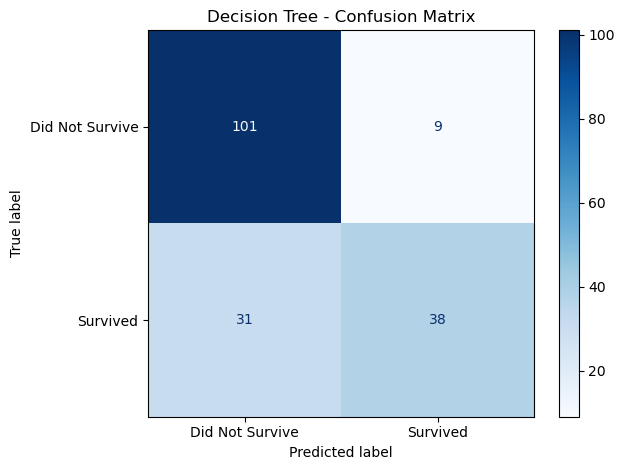

In [45]:
print(classification_report(
    y_test, y_pred, target_names=["Dis Not Survive", "Survived"], zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=["Did Not Survive", "Survived"], cmap="Blues"
)

plt.title("Decision Tree - Confusion Matrix")
plt.tight_layout()
plt.show()